# Dữ liệu âm thanh

Âm thanh lưu trong máy là một dãy số: biên độ sóng âm đo hàng nghìn lần mỗi giây. Nhìn dãy số đó thì rất khó biết đó là tiếng chuông hay tiếng nói. Bài này học sample rate, STFT để tìm các tần số trong từng đoạn ngắn của âm, và spectrogram, hình cho thấy tần số thay đổi theo thời gian, là dạng đầu vào thường dùng cho model âm thanh. Ta tự tạo một âm đổi cao độ giữa chừng để kiểm spectrogram có cho thấy đúng điều đó không.

> **Mục tiêu**
>
> - Tính thời lượng từ số mẫu và sample rate; đổi sample rate không bị aliasing.
> - Đọc spectrogram; hiểu window và hop của STFT.
> - Tự tính log-mel.
> - Chọn augmentation hợp với nhãn.

## Từ dao động đến dãy số

Microphone đo biến thiên áp suất theo thời gian, rồi thiết bị chuyển thành số. Waveform là dãy biên độ $x[n]$, trong đó $n$ là chỉ số mẫu, bắt đầu từ 0. Sample rate $f_s$ cho biết mỗi giây có bao nhiêu mẫu, đơn vị Hz, tức mẫu/giây. Thời điểm mẫu thứ $n$ là $t_n=n/f_s$ giây. Một file có $N$ mẫu đại diện khoảng thời gian $T=N/f_s$; mẫu cuối nằm tại $(N-1)/f_s$, ngay trước đầu khoảng tiếp theo.

Đoạn 3 giây ở 16 000 Hz một kênh có 48 000 mẫu; lưu 16 bit mỗi mẫu thì mỗi giây tốn 32 000 byte. Âm cao hơn nghĩa là dao động có tần số lớn hơn; tai người nghe được khoảng từ 20 Hz đến 20 000 Hz.

Biên độ float là số tương đối, không phải áp suất đo bằng pascal. WAV PCM 16-bit lưu số nguyên từ $-32\,768$ đến $32\,767$; chia cho $32\,768$ để đưa về khoảng $[-1,1)$, nếu quên thì biên độ lớn gấp hàng chục nghìn lần.

File stereo có hai kênh, đọc ra mảng `(N, 2)` hoặc `(2, N)` tùy thư viện; thời lượng tính theo trục mẫu, không theo tổng số phần tử. Lấy trung bình hai kênh là một cách downmix, nhưng hai kênh trái pha sẽ triệt tiêu nhau.

Ta dùng $f_s=2000$ Hz, một giây gồm 2000 mẫu. Nửa đầu là sine 200 Hz, nửa sau là sine 600 Hz, nên ta biết trước một biểu diễn đúng phải cho thấy gì: 200 Hz trong nửa giây đầu, 600 Hz trong nửa giây sau. Biên độ 0.7 và 0.4 giúp phân biệt thêm độ mạnh của hai đoạn.

In [ ]:
import numpy as np

sample_rate = 2000
num_samples = 2000
time = np.arange(num_samples) / sample_rate
waveform = np.where(
    time < 0.5,
    0.7 * np.sin(2 * np.pi * 200 * time),
    0.4 * np.sin(2 * np.pi * 600 * time),
)
duration = len(waveform) / sample_rate
interval_ms = 1000 / sample_rate
print(waveform.shape)
print(f"thời lượng = {duration:.3f} s")
print(f"khoảng mẫu = {interval_ms:.3f} ms")

(2000,)
thời lượng = 1.000 s
khoảng mẫu = 0.500 ms


Mỗi mẫu cách nhau 0.5 ms. Một chu kỳ 200 Hz dài $1/200=0.005$ giây, nên có 10 mẫu trong một chu kỳ; với 600 Hz chỉ khoảng 3.33 mẫu. Hình dưới phóng to 20 ms, vì vẽ cả một giây thì đường dao động rất khó đọc.



**Hỏi nhanh.** File WAV stereo 16 kHz được đọc thành mảng shape `(48000, 2)`, tức 48 000 mẫu cho mỗi kênh. File dài bao nhiêu giây?

- A. 0.000125 giây
- B. 1.5 giây
- C. 3 giây
- D. 6 giây

<details><summary>Đáp án</summary>

C. 3 giây

Thời lượng tính theo trục mẫu: $T = N/f_s = 48\,000/16\,000 = 3$ giây. 6 giây là chia tổng 96 000 phần tử cho sample rate, như thể hai kênh là hai đoạn nối tiếp nhau. 1.5 giây là chia thêm cho số kênh. $0.000125 = 2/16\,000$ là lấy nhầm trục kênh làm trục thời gian, lỗi hay gặp khi thư viện trả về `(2, N)` còn code lại giả định `(N, 2)`.

</details>

**Hỏi nhanh.** Microphone phải của một bản ghi stereo bị đấu ngược cực, nên kênh phải đúng bằng kênh trái đổi dấu. Downmix bằng cách lấy trung bình hai kênh thì được gì?

- A. Toàn số 0, vì hai kênh triệt tiêu nhau
- B. Giống kênh trái, vì trung bình giữ nguyên dạng sóng
- C. Biên độ gấp đôi kênh trái, vì hai kênh cộng lại
- D. Kênh trái đổi dấu, vì kênh phải chiếm ưu thế

<details><summary>Đáp án</summary>

A. Toàn số 0, vì hai kênh triệt tiêu nhau

Tại mọi mẫu, $(x + (-x))/2 = 0$. Bản mono thành im lặng, dù từng kênh vẫn có âm. Trung bình chỉ giữ dạng sóng khi hai kênh gần cùng pha. Gấp đôi là cộng lại mà quên dấu trừ. Hai kênh có biên độ bằng nhau, nên không kênh nào át kênh nào. Trước khi downmix, hãy so năng lượng của bản mono với từng kênh. Đôi khi chỉ cần giữ một kênh là đủ.

</details>

## Vì sao không lấy mẫu thưa tùy ý?

Hai dao động liên tục khác nhau có thể đi qua đúng những chấm lấy mẫu giống nhau. Khi đó thuật toán nhận các chấm không thể biết dao động gốc là cái nào. Hiện tượng này là aliasing (chồng phổ).

Để phục hồi một tín hiệu lý tưởng chỉ có tần số dưới $f_{max}$, ta cần $f_s>2f_{max}$. Mốc $f_s/2$ gọi là tần số Nyquist; ngay tại mốc ấy, một sine có pha đặc biệt còn có thể cho toàn số 0. Trong thiết bị thật, cần bộ lọc và khoảng chuyển tiếp, nên không thiết kế sát biên.

Thông tin quan trọng của giọng nói nằm dưới khoảng 8 kHz, nên 16 kHz là đủ; vì vậy nhiều model tiếng nói học ở 16 kHz, và file 44.1 kHz phải được resample về đúng 16 kHz trước khi đưa vào.

Với $f_s=1000$ Hz, cosine 350 Hz và cosine 650 Hz cho cùng dãy số: $650=1000-350$. Ta kiểm trên 20 mẫu; cosine được chọn để hai dãy giống nhau trực tiếp, không cần đổi dấu.

In [ ]:
alias_rate = 1000
sample_index = np.arange(20)
low_tone = np.cos(2 * np.pi * 350 * sample_index / alias_rate)
high_tone = np.cos(2 * np.pi * 650 * sample_index / alias_rate)
print(np.allclose(low_tone, high_tone))

True


Kết quả `True` có nghĩa là dữ liệu đầu vào đã mất khả năng phân biệt hai tần số; model mạnh hơn cũng không lấy lại được thông tin bị bỏ từ trước. Tổng quát, một thành phần $f$ nằm giữa $f_s/2$ và $f_s$ hiện ra ở $f_s-f$, như thể bị gập qua mốc Nyquist.



Lỗi này dễ gặp nhất khi giảm sample rate. Lấy một mẫu trong hai (`waveform[::2]`) đưa tín hiệu về 1000 Hz, Nyquist mới là 500 Hz, nên đoạn 600 Hz của ta sẽ hiện ra ở $1000-600=400$ Hz. [`resample_poly` của SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html) lọc thông thấp (low-pass) trước khi giữ ít mẫu hơn. Ta so biên độ tại 400 Hz trong nửa sau của hai kết quả, nơi bản gốc chỉ có 600 Hz:

In [ ]:
from scipy.signal import resample_poly

half_rate = sample_rate // 2
naive = waveform[::2]
filtered = resample_poly(waveform, up=1, down=2)
for name, signal in [("bỏ mẫu", naive), ("có lọc", filtered)]:
    tail = signal[len(signal) // 2:]
    amplitude = np.abs(np.fft.rfft(tail)) * 2 / len(tail)
    freqs = np.fft.rfftfreq(len(tail), d=1 / half_rate)
    print(f"{name}: {len(signal)} mẫu, biên độ ở 400 Hz = {amplitude[freqs == 400][0]:.3f}")

bỏ mẫu: 1000 mẫu, biên độ ở 400 Hz = 0.400
có lọc: 1000 mẫu, biên độ ở 400 Hz = 0.000


Hai kết quả cùng có 1000 mẫu. Bản bỏ mẫu chứa một âm 400 Hz biên độ 0.4, đúng bằng biên độ của đoạn 600 Hz, dù bản ghi không hề có âm 400 Hz. Bản có lọc mất đoạn 600 Hz, vì 1000 Hz không giữ được nó, nhưng không bịa ra âm mới; đoạn 200 Hz nằm dưới Nyquist mới nên được giữ. Mất một dải tần là điều phải chấp nhận khi giảm sample rate; âm giả trộn vào dải còn lại thì không.



Đổi sample rate trong biến hoặc header không phải resample. Nếu gắn nhãn 4000 Hz cho mảng 2000 mẫu, phần mềm phát nó trong 0.5 giây, nhanh và cao hơn. Muốn giữ đúng một giây ở 4000 Hz, phải tạo 4000 mẫu mới:

In [ ]:
new_rate = 4000
resampled = resample_poly(waveform, up=2, down=1)
print(f"đổi metadata: {len(waveform) / new_rate:.3f} s")
print(f"resample: {len(resampled) / new_rate:.3f} s")

đổi metadata: 0.500 s
resample: 1.000 s


Dòng đầu đổi ý nghĩa của trục thời gian; dòng sau chỉ đổi mật độ mẫu. Ở 4000 Hz, mảng mới biểu diễn được tới 2000 Hz, nhưng upsampling không bổ sung âm cao mà bản ghi cũ chưa từng có: dải 1000–2000 Hz của bản mới gần như trống.

**Hỏi nhanh.** Thu âm ở 8000 Hz mà không có bộ lọc chống aliasing, trong khi trong phòng có tiếng rít 5000 Hz. Trên spectrogram của bản ghi, tiếng rít hiện ra ở đâu?

- A. Ở 5000 Hz, đúng vị trí của nó
- B. Ở 1000 Hz, tức phần vượt quá Nyquist
- C. Không thấy, vì nó vượt Nyquist 4000 Hz
- D. Ở 3000 Hz, sau khi gập qua mốc Nyquist

<details><summary>Đáp án</summary>

D. Ở 3000 Hz, sau khi gập qua mốc Nyquist

5000 nằm giữa $f_s/2 = 4000$ và $f_s = 8000$, nên hiện ra ở $8000 - 5000 = 3000$ Hz, và trộn lẫn với âm thật cùng tần số. Trục tần số của bản ghi chỉ tới 4000 Hz, nên không thể có 5000 Hz. 1000 Hz là lấy $5000 - 4000$, tức gập sai mốc. “Không thấy” chỉ đúng khi có bộ lọc trước lúc lấy mẫu.

</details>

**Hỏi nhanh.** Clip 16 kHz dài 2 giây chứa tiếng còi 1000 Hz. Một bước tiền xử lý chỉ sửa header thành 24 kHz, giữ nguyên mảng. Phát lại, hoặc đưa vào model 24 kHz, thì clip ra sao?

- A. Dài 2 giây, còi 1000 Hz, vì mảng không đổi
- B. Dài khoảng 1.33 giây, còi 1500 Hz
- C. Dài khoảng 1.33 giây, còi 667 Hz
- D. Dài 3 giây, còi 1500 Hz

<details><summary>Đáp án</summary>

B. Dài khoảng 1.33 giây, còi 1500 Hz

Mảng có 32 000 mẫu. Đọc ở 24 kHz thì dài $32\,000/24\,000 \approx 1.33$ giây. Một chu kỳ của tiếng còi vẫn chiếm 16 mẫu, nay ứng với $16/24\,000$ giây, nên tần số thành 1500 Hz. Mọi thứ nhanh và cao lên 1.5 lần. 667 Hz là đổi tỉ lệ ngược chiều. 3 giây là nhân thay vì chia. Mảng không đổi, nhưng ý nghĩa thời gian của từng mẫu đã đổi.

</details>

## STFT: xem những tần số nào xuất hiện ở từng lúc

FFT biến một đoạn waveform thành các hệ số theo tần số. Nếu FFT toàn một giây, ta thấy cả 200 Hz và 600 Hz nhưng không biết chúng xuất hiện trước hay sau. Short-time Fourier transform (STFT) khắc phục bằng cách lấy từng frame ngắn, FFT từng frame, rồi xếp kết quả theo thời gian.

Ta chọn độ dài cửa sổ (window length) $L=200$ mẫu, tức 100 ms; bước nhảy (hop) $H=100$ mẫu, tức sau 50 ms lại bắt đầu frame mới. Frame liền nhau chồng lấp 100 mẫu. Không padding thì số frame là $F=1+\lfloor(N-L)/H\rfloor=19$.

Hop điều khiển mật độ cột thời gian; window length mới là độ dài tín hiệu được dùng để tính mỗi cột. Với tiếng nói ở 16 kHz, cấu hình hay gặp là window 25 ms (400 mẫu) và hop 10 ms (160 mẫu).

Nhiều thư viện mặc định `center=True`: đệm $L/2$ mẫu ở mỗi đầu để frame $j$ có tâm tại mẫu $jH$, khi đó $F=1+\lfloor N/H\rfloor$. Hai quy ước lệch nhau vài frame, đủ làm sai shape khi ghép với nhãn theo thời gian.



Trước FFT, nhân frame với một cửa sổ (window). Hann window làm hai đầu nhỏ dần, giảm gián đoạn giả khi FFT coi đoạn tín hiệu được lặp lại. Ta dùng bản Hann tuần hoàn $w[n]=\frac12(1-\cos(2\pi n/L))$, $0\leq n<L$. Đổi window làm thay đổi độ rộng đỉnh phổ, nên không thể xem nó là trang trí. Mỗi hệ số STFT là

$$S[k,j]=\sum_{n=0}^{L-1}x[jH+n]w[n]e^{-2\pi i kn/L}.$$

$j$ là frame, $k$ là bin tần số, $i$ trong số mũ là đơn vị ảo. Công thức chỉ là tổng các mẫu sau khi cân trọng số, so với những dao động chuẩn. Chưa cần tự tính số phức; `rfft` tính phần tần số không âm cho tín hiệu thực.

Với $L=200$, có $L/2+1=101$ bin, từ 0 đến 1000 Hz, cách nhau $f_s/L=10$ Hz. Đó là khoảng cách bin; khả năng tách hai đỉnh còn phụ thuộc window và độ dài đoạn, không chỉ bước trên trục. Ở 16 kHz với FFT 512 mẫu, các bin cách nhau $16000/512 = 31.25$ Hz; cấu hình 25 ms, 10 ms trên 1 giây cho $1 + \lfloor(1000 - 25)/10\rfloor = 98$ frame.

In [ ]:
from scipy.signal.windows import hann
from numpy.lib.stride_tricks import sliding_window_view

def stft_power(signal, rate, window_size=200, hop=100):
    frames = sliding_window_view(signal, window_size)[::hop]
    window = hann(window_size, sym=False)
    spectrum = np.fft.rfft(frames * window, axis=1)
    power = (np.abs(spectrum) / window.sum()) ** 2
    frequencies = np.fft.rfftfreq(window_size, d=1 / rate)
    centers = (np.arange(len(frames)) * hop + window_size / 2) / rate
    return power.T, frequencies, centers

power, frequencies, centers = stft_power(waveform, sample_rate)
print(power.shape)
peaks = np.argmax(power[:, [0, -1]], axis=0)
print(frequencies[peaks])
print(centers[[0, -1]].round(2))

(101, 19)
[200. 600.]
[0.05 0.95]


Ma trận có shape `(101, 19)`: hàng là tần số, cột là thời gian. Hai đỉnh ở frame đầu và cuối phải là 200 và 600 Hz; nếu đổi hai trục mà vẫn gán nhãn như cũ, hình sẽ sai dù code vẽ không báo lỗi. Ta chia biên độ phổ cho tổng window để thang số dễ đọc, rồi bình phương. `power` ở đây là bình phương biên độ tương đối, **không phải** mật độ phổ công suất có đơn vị watt/Hz.

**Hỏi nhanh.** Tiếng nói 16 kHz, window 400 mẫu tức 25 ms, không zero-padding. `rfft` của một frame cho bao nhiêu bin, và các bin cách nhau bao nhiêu Hz?

- A. 200 bin, cách nhau 40 Hz
- B. 201 bin, cách nhau 20 Hz
- C. 400 bin, cách nhau 20 Hz
- D. 201 bin, cách nhau 40 Hz

<details><summary>Đáp án</summary>

D. 201 bin, cách nhau 40 Hz

Có $L/2 + 1 = 201$ bin, từ 0 Hz đến Nyquist 8000 Hz, cách nhau $f_s/L = 16\,000/400 = 40$ Hz. 200 là quên bin 0 Hz hoặc bin Nyquist. 20 Hz là chia Nyquist cho 400 bin. 400 là số điểm của `fft` đầy đủ, mà với tín hiệu thực, nửa sau chỉ là ảnh đối xứng của nửa đầu.

</details>



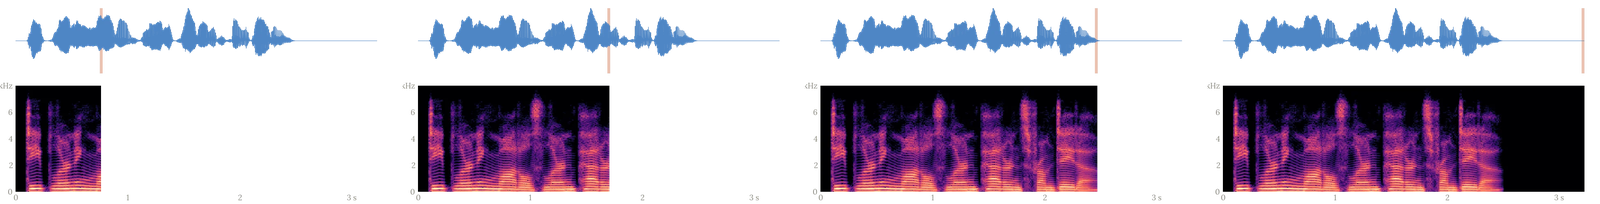

Window dài cho nhiều chu kỳ hơn để phân biệt tần số gần nhau, nhưng gộp thay đổi trong thời gian dài hơn. Window ngắn định vị tiếng gõ nhanh hơn, nhưng các đỉnh tần số rộng hơn. Tiếng Việt có thanh điệu: cùng một âm tiết, đường cao độ khác nhau là từ khác nhau, nên model nhận dạng phải giữ được thông tin cao độ.

Zero-padding trước FFT tăng số điểm vẽ trên trục tần số, không tăng thời gian quan sát và không tự tách hai âm quá gần. [`ShortTimeFFT` của SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.ShortTimeFFT.html) là lựa chọn thư viện cho quy trình có STFT/ISTFT; khi đối chiếu, phải khớp window, padding, tâm frame và scaling.

**Hỏi nhanh.** Giữ window length 200 mẫu, giảm hop từ 100 xuống 50 mẫu trên waveform của bài. Điều gì thay đổi trực tiếp?

- A. Có nhiều frame hơn trên cùng bản ghi
- B. Mỗi frame quan sát một đoạn dài gấp đôi
- C. Nyquist frequency tăng lên gấp đôi
- D. Mỗi bin tần số rộng ra gấp đôi

<details><summary>Đáp án</summary>

A. Có nhiều frame hơn trên cùng bản ghi

Hop là bước trượt giữa hai frame. Số frame từ 19 thành $1 + \lfloor 1800/50\rfloor = 37$, nên chi phí tính và bộ nhớ tăng gần gấp đôi. Window và sample rate giữ nguyên, nên thời gian quan sát mỗi frame, Nyquist và khoảng cách giữa các bin đều không đổi.

</details>

**Hỏi nhanh.** Hai bài toán có cùng sample rate. Bài (1) định vị tiếng gõ phím chỉ kéo dài vài mili giây. Bài (2) phân biệt hai nốt nhạc ngân dài, cao độ chênh nhau vài Hz. Nên chọn window thế nào?

- A. Bài (1) dùng window dài, bài (2) dùng window ngắn
- B. Như nhau, vì window chỉ đổi số cột thời gian
- C. Bài (1) dùng window ngắn, bài (2) dùng window dài
- D. Cả hai dùng window dài, rồi giảm hop để định vị

<details><summary>Đáp án</summary>

C. Bài (1) dùng window ngắn, bài (2) dùng window dài

Window ngắn gộp ít thời gian, nên tiếng gõ không bị nhòe sang frame lân cận. Window dài chứa nhiều chu kỳ, nên hai đỉnh gần nhau tách được. Số cột do hop quyết định, còn window quyết định sự đánh đổi giữa thời gian và tần số. Giảm hop chỉ thêm cột. Mỗi cột vẫn gộp cả một window dài, nên tiếng gõ vẫn nhòe.

</details>



## Mel và log-mel: gộp vùng tần số, nén thang số

Một spectrogram có hàng trăm bin; ta có thể gộp chúng bằng các bộ lọc tam giác. Mel filter bank đặt các bộ lọc trên một thang tần số gần với cách nghe cao độ, thay vì đều theo Hz. Có nhiều quy ước mel; bài này chọn công thức HTK

$$m(f)=2595\log_{10}(1+f/700).$$

$f$ có đơn vị Hz, $m$ là tọa độ mel. Ta đặt 22 điểm đều theo mel, đổi lại sang Hz, tạo 20 tam giác giữa từng bộ ba điểm. Mel band $b$ ở frame $j$ là $M[b,j]=\sum_k W[b,k]P[k,j]$. $W$ có shape `(20, 101)`, nên phép nhân $WP$ cho `(20, 19)`. Model tiếng nói thường dùng 80 hoặc 128 band trên dải tới 8 kHz; bài dùng 20 band vì trục chỉ tới 1000 Hz.

Tam giác trong bài có đỉnh bằng 1, không chuẩn hóa diện tích; kết quả không nhất thiết bằng mặc định Slaney của librosa. [Tài liệu mel của librosa](https://librosa.org/doc/main/api/generated/librosa.mel_frequencies.html) giải thích khác biệt này.

In [ ]:
def mel_filter_bank(frequency_grid, num_bands):
    max_mel = 2595 * np.log10(1 + frequency_grid[-1] / 700)
    mel_edges = np.linspace(0, max_mel, num_bands + 2)
    hz_edges = 700 * (10 ** (mel_edges / 2595) - 1)
    filters = np.zeros((num_bands, len(frequency_grid)))
    for band in range(num_bands):
        left, middle, right = hz_edges[band:band + 3]
        rising = (frequency_grid - left) / (middle - left)
        falling = (right - frequency_grid) / (right - middle)
        filters[band] = np.maximum(0, np.minimum(rising, falling))
    return filters

filters = mel_filter_bank(frequencies, num_bands=20)
mel_power = filters @ power
reference_power = max(float(mel_power.max()), 1e-12)
log_mel = 10 * np.log10(np.maximum(mel_power, 1e-12) / reference_power)
print(filters.shape, log_mel.shape)
print(np.round([log_mel.min(), log_mel.max()], 1))
print(np.isfinite(log_mel).all())

(20, 101) (20, 19)
[-112.1    0. ]
True


Log làm các vùng yếu dễ nhìn hơn và giảm chênh lệch thang số. Ta dùng $10\log_{10}(M/M_{\mathrm{ref}})$ vì $M$ là đại lượng bình phương biên độ; nếu lấy log của biên độ trực tiếp thì dùng hệ số 20. Mốc của hình là mel power lớn nhất của **chính clip này**, nên 0 dB nghĩa là ngang đỉnh clip, không phải mức âm thanh tuyệt đối. Chặn dưới trước log tránh `-inf` ở im lặng. Pretrained model có thể dùng log tự nhiên, dải động hay mốc khác; phải dùng processor của nó, không thay bằng công thức này rồi giữ nguyên tên.

MFCC, đặc trưng kinh điển của tiếng nói, đi thêm một bước: lấy log-mel rồi biến đổi cosine rời rạc (DCT) và giữ khoảng 13 hệ số đầu, những hệ số tóm hình dạng của phổ. Nhiều model học sâu ngày nay dùng thẳng log-mel.





**Hỏi nhanh.** Mel power có phần tử bằng 0. Trước khi lấy log, vì sao người ta thường tính $\log(\max(\text{power}, \varepsilon))$ với $\varepsilon > 0$?

- A. Để mọi mel band có mean bằng 0
- B. Để log hữu hạn ở những ô có power bằng 0
- C. Để tăng độ phân giải tần số của STFT
- D. Để resample waveform về sample rate của model

<details><summary>Đáp án</summary>

B. Để log hữu hạn ở những ô có power bằng 0

$\log 0 = -\infty$, và chỉ một ô `-inf` cũng đủ làm mean, loss và gradient thành `nan`. Chặn sàn là một xử lý số học, không thay được normalization, resampling hay độ dài window. $\varepsilon$ quyết định sàn của log. Trong bài, $10^{-12}$ ứng với $-120$ dB so với power 1, nên phải ghi nó cùng cấu hình.

</details>

**Hỏi nhanh.** Bộ lọc của bài đặt 22 mốc đều theo mel trên dải 0–1000 Hz. Hai mốc đầu cách nhau khoảng 30 Hz. Hai mốc cuối cách nhau khoảng bao nhiêu?

- A. Khoảng 70 Hz, vì band cao rộng hơn
- B. Khoảng 30 Hz, vì các mốc được chia đều
- C. Khoảng 15 Hz, vì band cao hẹp hơn
- D. Khoảng 1000 Hz, vì band cuối phủ cả trục

<details><summary>Đáp án</summary>

A. Khoảng 70 Hz, vì band cao rộng hơn

Các mốc đều theo mel, không đều theo Hz. $m(f)$ tăng chậm dần khi $f$ lớn, nên cùng một bước mel ứng với khoảng Hz rộng dần, và hai mốc cuối là khoảng 930 và 1000 Hz. Band cao vì thế gom nhiều bin STFT hơn, giống như tai người phân biệt cao độ kém dần ở tần số cao. 30 Hz là coi mel như Hz. 15 Hz là hiểu ngược chiều nén của thang log.

</details>

Tính thử một band: ba bin có power $(1,4,1)$, bộ lọc tam giác có trọng số $(0.5,1,0.5)$. Power sau gộp là $0.5\cdot1+1\cdot4+0.5\cdot1=5$. Nếu mốc power là 5 thì band này bằng $10\log_{10}(5/5)=0$ dB; band khác có power 0.5 thì bằng $10\log_{10}(0.1)=-10$ dB. Đây là tỉ số power, không phải “âm lượng giảm 10 lần” theo cảm giác nghe.

## Chuẩn hóa waveform và file im lặng

Peak normalization chia cho biên độ lớn nhất để clip vừa một dải số; RMS đo mức dao động điển hình, $\sqrt{\frac1N\sum_n x[n]^2}$.

Chuẩn hóa mỗi clip có thể xóa thông tin âm lượng hữu ích. Một máy đang chạy yếu và một máy chạy mạnh có thể khác chính ở mức dao động ấy. Ta thử peak normalization, kèm bảo vệ file im lặng:

In [ ]:
def peak_normalize(signal):
    peak = float(np.max(np.abs(signal)))
    return signal / max(peak, 1e-8)

tiny_wave = np.array([0.0, 0.2, -0.4, 0.2])
normalized = peak_normalize(tiny_wave)
print(normalized.round(2))
print(peak_normalize(np.zeros(4)))
print(f"RMS trước = {np.sqrt(np.mean(tiny_wave ** 2)):.3f}")

[ 0.   0.5 -1.   0.5]
[0. 0. 0. 0.]
RMS trước = 0.245


Ta được $(0,0.5,-1,0.5)$; RMS trước bằng $\sqrt{(0+0.04+0.16+0.04)/4}=\sqrt{0.06}$. File im lặng giữ toàn 0. Chuẩn hóa đặc trưng bằng mean/std của tập train ở bài 7.2 có mục đích khác: làm thang đầu vào của bộ phân loại ổn định. Hai thao tác không thay thế nhau.

**Hỏi nhanh.** Đề phân loại máy bơm “bình thường” và “kẹt”, ghi bằng cùng một microphone đặt cố định. Máy kẹt rung mạnh hơn: dạng sóng gần giống máy bình thường, nhưng biên độ gấp khoảng 3 lần. Một đội peak-normalize từng clip trước khi tính log-mel. Chuyện gì xảy ra?

- A. Model học dễ hơn, vì mọi clip về cùng thang
- B. Khác biệt chính giữa hai lớp bị xóa trước khi vào model
- C. Không ảnh hưởng gì, vì log-mel tự bù lại biên độ
- D. Chỉ clip im lặng bị ảnh hưởng, do chia cho 0

<details><summary>Đáp án</summary>

B. Khác biệt chính giữa hai lớp bị xóa trước khi vào model

Peak normalization chia mỗi clip cho đỉnh của chính nó. Hai clip chỉ khác nhau một hệ số biên độ vì vậy trở nên gần như trùng nhau. Log-mel lấy mốc là đỉnh của clip cũng xóa đúng hệ số ấy. Với mốc cố định, biên độ gấp 3 chỉ là dịch $20\log_{10} 3 \approx 9.5$ dB, và model đọc được nếu đầu vào còn giữ nó. Chia cho 0 đã được chặn bằng `max(peak, 1e-8)`. Ở đây nên giữ thang chung cho mọi clip, rồi chuẩn hóa đặc trưng bằng thống kê của train.

</details>



## Augmentation

Nếu nhãn là “tiếng chuông”, giảm âm lượng vừa phải có thể giữ nhãn, nhưng thêm nhiễu quá lớn khiến chuông không còn nghe được. Nếu nhãn là cao độ nốt nhạc, pitch shift làm thay đổi nhãn. Nếu nhãn là câu nói, crop mất từ sẽ làm transcript cũ không còn đúng. Phải hỏi “sau biến đổi, đáp án có còn là đáp án cũ?” trước khi chọn phép biến đổi.

Trộn tiếng ồn quán cà phê vào bản ghi sạch dạy model bền với môi trường ồn. Phát nhanh 1.1 lần giúp model quen người nói nhanh, nhưng cũng làm giọng cao lên, nên chỉ hợp khi nhãn không phụ thuộc cao độ.

Time masking và frequency masking trên log-mel là hai thành phần của [SpecAugment](https://arxiv.org/abs/1904.08779). Chúng che một vùng biểu diễn trong lúc train, để mô hình bớt lệ thuộc vào một mảnh nhỏ. Mức che phải vừa với thời lượng và nhiệm vụ; không áp ngẫu nhiên vào validation.

Nếu đầu vào đã chuẩn hóa về mean 0, điền 0 là điền giá trị trung bình, còn trên thang dB tương đối 0 là đỉnh clip. Cùng một dòng `array[...] = 0` có thể mang hai nghĩa rất khác.



**Hỏi nhanh.** Nhãn là transcript đầy đủ của câu nói. Crop ngẫu nhiên làm mất nửa cuối clip, nhưng vẫn giữ transcript cũ. Làm vậy có hợp lệ không?

- A. Có, vì augmentation không bao giờ đổi nhãn
- B. Có, nếu sample rate vẫn giữ nguyên
- C. Không, vì phần chữ cuối không còn trong âm thanh
- D. Có, nếu model là Transformer đủ lớn

<details><summary>Đáp án</summary>

C. Không, vì phần chữ cuối không còn trong âm thanh

Augmentation hợp lệ khi đáp án cũ vẫn đúng với input mới. Clip còn lại không chứa nửa sau câu nói, nên model bị dạy “nghe” ra những chữ không có trong âm thanh, tức là được khuyến khích bịa chữ. Sample rate hay kiến trúc đều không thay đổi được điều đó. Muốn crop cho ASR, phải cắt theo dấu thời gian của từng từ, và cắt transcript tương ứng.

</details>

**Hỏi nhanh.** Nhãn là danh tính người nói, gồm 10 người trong một câu lạc bộ. Phép augmentation nào dễ làm sai nhãn nhất?

- A. Tăng hoặc giảm âm lượng 3 dB
- B. Trộn thêm tiếng quạt máy ở mức rất nhỏ
- C. Dịch clip sớm hoặc muộn 0.2 giây
- D. Pitch shift giọng lên 4 bán cung

<details><summary>Đáp án</summary>

D. Pitch shift giọng lên 4 bán cung

Cao độ và âm sắc là một phần danh tính của giọng. Đẩy giọng lên 4 bán cung có thể làm giọng người này giống người khác, nên nhãn cũ không còn chắc đúng. Đổi âm lượng vài dB, thêm ồn nhỏ hay dịch thời gian đều giữ nguyên người nói, và còn mô phỏng những biến đổi có thật khi micro ở xa hay gần. Cũng phép pitch shift ấy lại có thể hợp lệ với nhãn “có tiếng người hay không”.

</details>

## Khi đi thi

- Đọc header của mọi file trước model đầu tiên: sample rate, số kênh, thời lượng; đếm clip hỏng và clip im lặng.
- Dùng checkpoint thì resample về đúng sample rate của nó và dùng processor đi kèm.
- Chia theo bản ghi gốc trước khi cắt đoạn.

## Tóm tắt

- Waveform cần đi cùng sample rate: $T=N/f_s$. Aliasing xảy ra trước mô hình; giảm sample rate phải lọc trước, tăng sample rate không thêm âm cao.
- STFT cắt frame, nhân window rồi FFT. Window và hop trả lời hai câu hỏi khác nhau về thời gian.
- Spectrogram giữ thời gian và tần số; mel gộp tần số, log nén thang power. Quy ước và mốc log phải được ghi rõ.
- Chuẩn hóa và augmentation cần giữ thông tin liên quan đến nhãn, có bảo vệ im lặng và có cấu hình tái lập.

## Kiểm tra cuối bài

**Câu 1.** Đề phân loại tiếng chim, và nhiều loài chỉ khác nhau ở các nốt 9–11 kHz. Dữ liệu ghi ở 44.1 kHz, còn checkpoint audio có sẵn nhận 16 kHz. Resample đúng chuẩn về 16 kHz rồi fine-tune thì sao?

- A. Ổn, vì bộ lọc chống aliasing giữ lại dải 9–11 kHz
- B. Ổn, vì dải 9–11 kHz hiện ra ở 5–7 kHz, vẫn tách được
- C. Mất dải 9–11 kHz, nên cần đặc trưng ở sample rate cao hơn
- D. Mất dải 9–11 kHz, nhưng upsample lại lên 44.1 kHz sẽ khôi phục

<details><summary>Đáp án</summary>

C. Mất dải 9–11 kHz, nên cần đặc trưng ở sample rate cao hơn

Ở 16 kHz, Nyquist là 8 kHz. Resample đúng chuẩn lọc bỏ mọi thứ trên khoảng 8 kHz, nên bằng chứng phân biệt loài biến mất trước khi vào model. Chỉ khi bỏ mẫu mà không lọc, dải 9–11 kHz mới gập về 5–7 kHz, và khi đó nó trộn với âm thật ở dải ấy. Upsample sau đó không tạo lại được thứ đã bị lọc. Hướng hợp lý là tự tính log-mel ở 32 kHz hoặc 44.1 kHz cho một model riêng, hoặc dùng checkpoint train ở sample rate cao, rồi so trên validation với baseline 16 kHz.

</details>

**Câu 2.** Một tập dữ liệu trộn bản ghi điện thoại 8 kHz với bản ghi studio 44.1 kHz, còn checkpoint nhận 16 kHz. Đưa hai nguồn về 16 kHz thế nào cho đúng?

- A. 44.1 kHz thì resample có lọc, 8 kHz thì upsample, dải trên 4 kHz vẫn trống
- B. 44.1 kHz thì lấy 1 mẫu mỗi 3, 8 kHz thì upsample, dải trên 4 kHz vẫn trống
- C. 44.1 kHz thì resample có lọc, 8 kHz thì upsample để khôi phục dải trên 4 kHz
- D. 44.1 kHz thì lấy 1 mẫu mỗi 3, 8 kHz thì upsample để khôi phục dải trên 4 kHz

<details><summary>Đáp án</summary>

A. 44.1 kHz thì resample có lọc, 8 kHz thì upsample, dải trên 4 kHz vẫn trống

Downsampling giảm số mẫu, và phải lọc thông thấp trước, nếu không âm trên 8 kHz sẽ gập vào dải còn lại. Hơn nữa, $44\,100/3 = 14\,700$ Hz, không phải 16 kHz. Upsampling chỉ làm mảng khớp với đầu vào mà model cần. Bản ghi 8 kHz chưa từng chứa gì trên 4 kHz, nên dải ấy vẫn trống. Vì hai nguồn khác dải tần, nên xem riêng điểm validation theo từng nguồn.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=6)

</details>

**Câu 3.** Clip 1 giây ở 16 kHz, window 400 mẫu, hop 160 mẫu. Số frame STFT khi không padding, và khi `center=True`, tức đệm 200 mẫu mỗi đầu, lần lượt là bao nhiêu?

- A. 97 và 100
- B. 98 và 100
- C. 100 và 101
- D. 98 và 101

<details><summary>Đáp án</summary>

D. 98 và 101

Số vị trí của một cửa sổ trượt là $\lfloor(N + 2p - L)/H\rfloor + 1$, đúng công thức của convolution một chiều với kernel $L$, stride $H$ và padding $p$. Không padding thì được $\lfloor 15\,600/160\rfloor + 1 = 97 + 1 = 98$. Với $p = 200$ thì được $\lfloor 16\,000/160\rfloor + 1 = 101$, và `torch.stft` với `center=True` cho đúng shape `(201, 101)`. 97 là quên cộng 1. 100 là lấy $N/H$ mà quên frame đầu. Khi ghép nhãn theo frame, lệch ba frame giữa hai quy ước cũng đủ làm sai shape.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.2(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=6)

</details>

**Câu 4.** STFT của bài, với window 200, hop 100 và Hann, có thể viết bằng `nn.Conv1d(1, 202, kernel_size=200, stride=s, bias=False)` với 202 kernel cố định, gồm 101 cosine và 101 sine đã nhân Hann. Với waveform shape `(1, 1, 2000)`, `s` bằng bao nhiêu, và output có shape gì?

- A. `s=1`, output `(1, 202, 1801)`
- B. `s=100`, output `(1, 202, 19)`
- C. `s=100`, output `(1, 101, 19)`
- D. `s=200`, output `(1, 202, 10)`

<details><summary>Đáp án</summary>

B. `s=100`, output `(1, 202, 19)`

Stride của convolution là bước dời kernel, đúng vai trò của hop, nên có $\lfloor(2000 - 200)/100\rfloor + 1 = 19$ vị trí. Mỗi bin cần cả phần thực từ cosine lẫn phần ảo từ sine, nên có 202 kênh ra. Lấy tổng bình phương của cặp kênh cùng bin, chia cho bình phương tổng của window, thì được lại đúng ma trận `(101, 19)` của `stft_power`. `s=1` trượt từng mẫu, ra 1801 cột. `s=200` đặt hop bằng window, mất phần chồng lấp, và chỉ còn 10 frame. Viết STFT thành convolution cho phép tính spectrogram trên GPU ngay trong model.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 201](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=73)

</details>

**Câu 5.** Đề cho mỗi mẫu là một chuỗi 500 giá trị cảm biến, không ghi sample rate. Một đội cắt frame dài 50, hop 25, rồi lấy `rfft` của mỗi frame làm token cho Transformer. Có bao nhiêu token, và trục tần số của mỗi token đọc thế nào?

- A. 20 token, bin $k$ ứng với $10k$ Hz
- B. 20 token, bin $k$ ứng với $k/50$ chu kỳ mỗi mẫu
- C. 19 token, bin $k$ ứng với $k/50$ chu kỳ mỗi mẫu
- D. 19 token, bin $k$ ứng với $10k$ Hz

<details><summary>Đáp án</summary>

C. 19 token, bin $k$ ứng với $k/50$ chu kỳ mỗi mẫu

Có $\lfloor(500 - 50)/25\rfloor + 1 = 19$ token, mỗi token 26 bin. 20 là lấy $500/25$. Không có $f_s$ thì chỉ biết bin $k$ ứng với $k/L$ chu kỳ mỗi mẫu. Muốn đổi ra Hz phải nhân với $f_s$, mà đề không cho. $10k$ Hz là ngầm coi 500 mẫu dài đúng một giây. Nếu mọi mẫu có chung sample rate thì model vẫn học được, nhưng không được ghi Hz lên hình hay đặt dải mel theo Hz khi chưa biết $f_s$.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=7)

</details>

**Câu 6.** Window 20 ms, tức 320 mẫu, ở 16 kHz. Zero-pad mỗi frame lên 640 điểm trước khi FFT. Điều nào đúng?

- A. Các bin cách nhau 25 Hz, còn độ phân giải thật không đổi
- B. Các bin cách nhau 25 Hz, và tách được hai âm cách nhau 30 Hz
- C. Các bin cách nhau 100 Hz, còn độ phân giải thật không đổi
- D. Các bin cách nhau 50 Hz, và Nyquist tăng lên 16 kHz

<details><summary>Đáp án</summary>

A. Các bin cách nhau 25 Hz, còn độ phân giải thật không đổi

$16\,000/640 = 25$ Hz thay vì $16\,000/320 = 50$ Hz, nên lưới tần số dày gấp đôi. Zero-padding không thêm mẫu thật, nên thời gian quan sát vẫn là 20 ms. Đỉnh chính của Hann trong 20 ms rộng khoảng 200 Hz giữa hai điểm 0, nên hai âm cách nhau 30 Hz vẫn nhập thành một đỉnh. 100 Hz là đổi tỉ lệ ngược chiều. Nyquist chỉ phụ thuộc $f_s$.

</details>

**Câu 7.** Biên độ của một âm giảm còn 1/10. Trên log-mel tính theo $10\log_{10}$ của power, band chứa âm ấy giảm bao nhiêu dB?

- A. 10 dB
- B. 20 dB
- C. 40 dB
- D. 100 dB

<details><summary>Đáp án</summary>

B. 20 dB

Power tỉ lệ với bình phương biên độ, nên còn $1/100$. Vậy $10\log_{10}(0.01) = -20$ dB, cũng bằng $20\log_{10}(0.1)$ tính trên biên độ. 10 dB là áp hệ số 10 cho tỉ số biên độ. 40 dB là áp hệ số 20 cho tỉ số power đã bình phương. 100 là đọc tỉ số power như số dB.

</details>

**Câu 8.** Model được train trên đặc trưng `np.log(mel + 1e-6)`. Khi viết code nộp bài, một bạn lại tính `10 * np.log10(mel + 1e-6)`, rồi dùng nguyên mean và std của tập train. Đầu vào thay đổi thế nào?

- A. Không đổi, vì log nào cũng đơn điệu
- B. Mọi giá trị bị dịch đi một hằng số
- C. Chỉ những ô im lặng thay đổi, vì sàn khác
- D. Mọi giá trị bị nhân khoảng 4.34

<details><summary>Đáp án</summary>

D. Mọi giá trị bị nhân khoảng 4.34

$10\log_{10} z = \frac{10}{\ln 10}\ln z \approx 4.34\ln z$, nên mọi giá trị bị nhân 4.34. Trừ mean, chia std của train không bù được, vì các thống kê ấy tính trên thang $\ln$. Đơn điệu thì giữ thứ tự, nhưng model nhạy với thang. Đổi mốc tham chiếu thì mới là dịch một hằng số. Sàn $10^{-6}$ cũng bị nhân như mọi ô khác. Lỗi này không gây exception. Cách bắt là so đặc trưng của cùng một file giữa script train và script nộp.

</details>

**Câu 9.** Một đội chép cấu hình SpecAugment từ một recipe dùng 80 mel band. Mỗi frequency mask rộng $f$ band, với $f$ chọn đều trong các số nguyên $0, 1, \dots, 27$. Log-mel của đội chỉ có 20 band. Khoảng bao nhiêu phần lần che sẽ phủ kín cả 20 band?

- A. 0%, vì mask luôn hẹp hơn trục tần số
- B. Khoảng 29%, tức 8/28
- C. Khoảng 34%, tức 27/80
- D. Khoảng 71%, tức 20/28

<details><summary>Đáp án</summary>

B. Khoảng 29%, tức 8/28

Mọi $f \ge 20$ đều che kín trục. Các giá trị từ 20 đến 27 là 8 trong 28 giá trị, khoảng 29%. Khi đó cả clip thành một mảng hằng mà vẫn mang nhãn cũ, nên model bị dạy đoán nhãn từ một input không còn thông tin gì. 27/80 là tỉ lệ trục bị che tối đa trong recipe gốc, không phải xác suất trên trục 20 band. 20/28 là phần mask **không** che kín. Độ rộng mask phải co theo số band: giữ tỉ lệ $27/80$ thì còn tối đa khoảng 7 band.

</details>

**Câu 10.** Lớp “ho” được thu bằng điện thoại 8 kHz rồi upsample lên 16 kHz. Lớp “không ho” được thu trực tiếp ở 16 kHz. CNN trên log-mel đạt 99% trên validation. Nên kiểm gì trước khi tin con số này?

- A. Train thêm epoch, xem validation có lên 100% không
- B. Thêm SpecAugment để model bớt học thuộc lòng
- C. Lọc mọi clip về dưới 4 kHz rồi đánh giá lại
- D. Đổi sang model lớn hơn để xác nhận kết quả

<details><summary>Đáp án</summary>

C. Lọc mọi clip về dưới 4 kHz rồi đánh giá lại

Mọi clip “ho” có dải trên 4 kHz gần như trống, còn clip “không ho” thì không. Model có thể chỉ học “dải cao trống thì là ho”. Đưa mọi clip qua cùng dải dưới 4 kHz rồi đánh giá lại. Nếu điểm rơi mạnh, model đã học thiết bị thu chứ không học tiếng ho. Thêm epoch, SpecAugment hay model lớn hơn đều không đổi được tương quan giữa nguồn thu và nhãn, vì tương quan ấy có cả trong train lẫn validation.

</details>

## Đọc thêm

- Julius O. Smith — [*Spectral Audio Signal Processing*](https://www.dsprelated.com/freebooks/sasp/). Đọc các mục DFT, window và STFT để hiểu vì sao độ dài frame và hình cửa sổ ảnh hưởng phổ.
- SciPy — [`ShortTimeFFT`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.ShortTimeFFT.html) và [`resample_poly`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html). Tra hợp đồng trục, scaling và low-pass filter khi dùng thư viện.
- librosa — [mel frequencies](https://librosa.org/doc/main/api/generated/librosa.mel_frequencies.html). Đối chiếu HTK và Slaney trước khi so hai log-mel.
- Park và cộng sự — [*SpecAugment*](https://arxiv.org/abs/1904.08779). Đọc cách che theo thời gian và theo tần số trên đặc trưng; chọn mức che theo nhiệm vụ cụ thể.

Nguồn âm thanh: các câu tiếng Anh trong hình động được đọc bằng giọng tổng hợp có sẵn của Windows (Microsoft Zira, Microsoft David).